# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = 1920 * 1080 * 3 * 1 / 1024**2          # W x H x C x B (8 bits = 1 byte per channel)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60                 # f x T

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = 400 * frames_per_day * (1920 * 1080 * 3) / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = 400 * (10 * 24 * 60 * 60) * (640 * 360 * 3) / 1024**4
pct_pixels_remaining = 100 * (640 * 360) / (1920 * 1080)

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_ **Spatial:** at 640×360 only 11.11% of the pixels remain, so fine detail such as a licence plate, a face or a small object in someone's hand is averaged away by interpolation. Upscaling later can only guess new pixels from neighbours, so the detail cannot be recovered. **Temporal:** at 10 fps the gap between frames is 100 ms instead of 33 ms, so fast motion such as a person starting to run or a brief hand movement may fall between frames. Objects then jump further between frames, which makes matching them across frames (the correspondence problem) harder and can make a sequence of events ambiguous. A momentary event, like a thrown object, may not be captured at all.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

Contrast before: 0.609  ->  after: 1.000


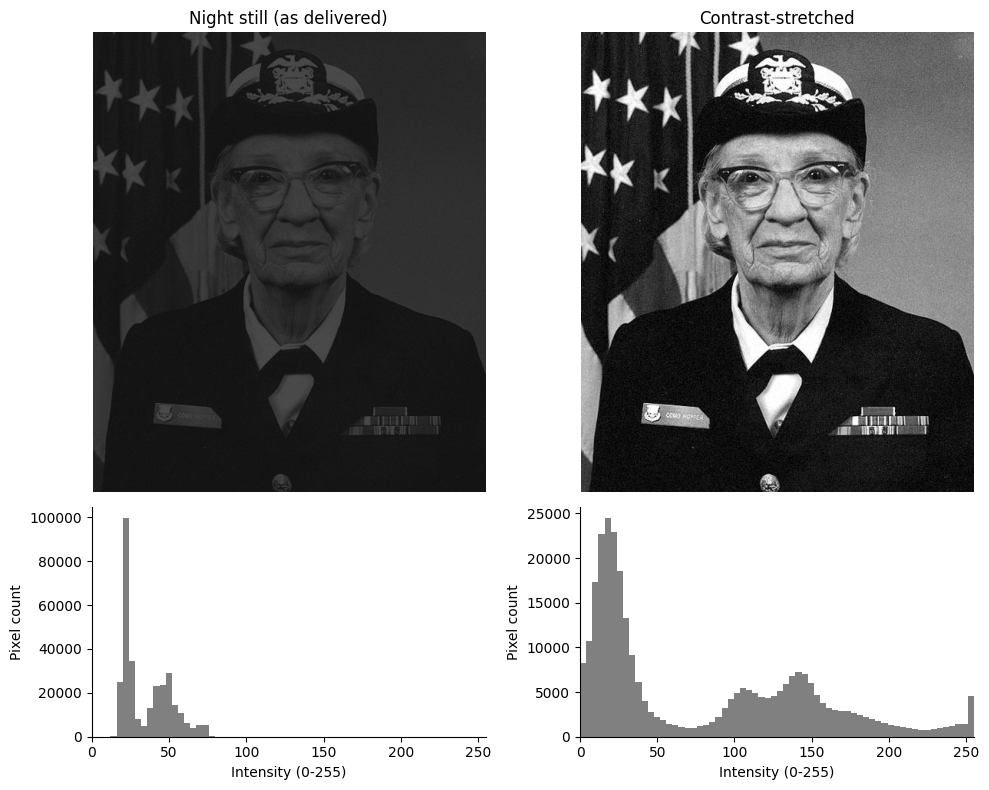

In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - lo) / (hi - lo) * 255, 0, 255)

lo2, hi2 = np.percentile(stretched, [1, 99])
c_after = michelson(hi2, lo2)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
for col, (im, title) in enumerate([(night_still, "Night still (as delivered)"), (stretched, "Contrast-stretched")]):
    axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(title); axes[0, col].axis("off")
    axes[1, col].hist(im.ravel(), bins=64, range=(0, 255), color="gray")
    axes[1, col].set_xlim(0, 255)
    axes[1, col].set_xlabel("Intensity (0-255)"); axes[1, col].set_ylabel("Pixel count")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_ The histogram is **narrow and shifted to the dark end**: all pixels sit in a small low-intensity band (roughly 18 to 75 out of 255), with nothing in the bright half. That is a dark, low-contrast (under-exposed) image, with a Michelson contrast of about 0.6 on the percentile measure, and it is not clipped. Stretching is a linear remap of the occupied range onto 0–255. The ordering and relative differences between pixels are preserved, so no new information is added, but the differences already present are now spread over a range the eye can distinguish. Murkiness was a display problem, not a data problem. A histogram only counts how many pixels have each intensity and throws away *where* they are, so very different pictures can share one histogram. It can diagnose exposure and contrast, but it cannot tell you what is in the scene.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing: 68.7 s -> 78.1 s
Running : 78.6 s -> 86.0 s
Audio event   : frame 2250 (t = 75.00 s)
Lighting event: frame 3000 (t = 100.00 s)


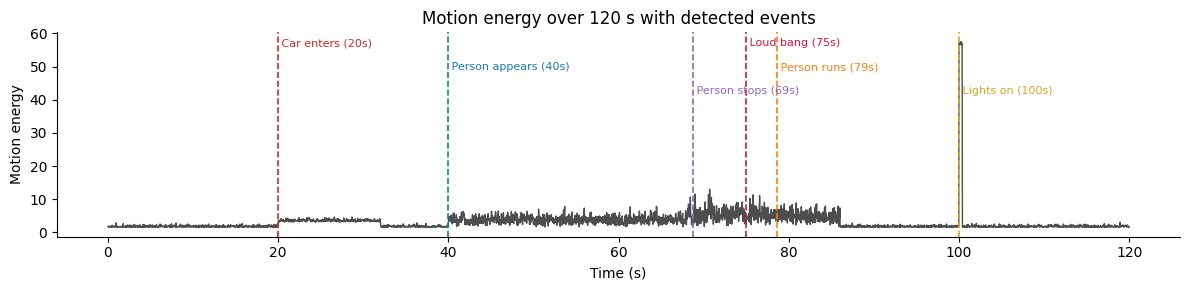

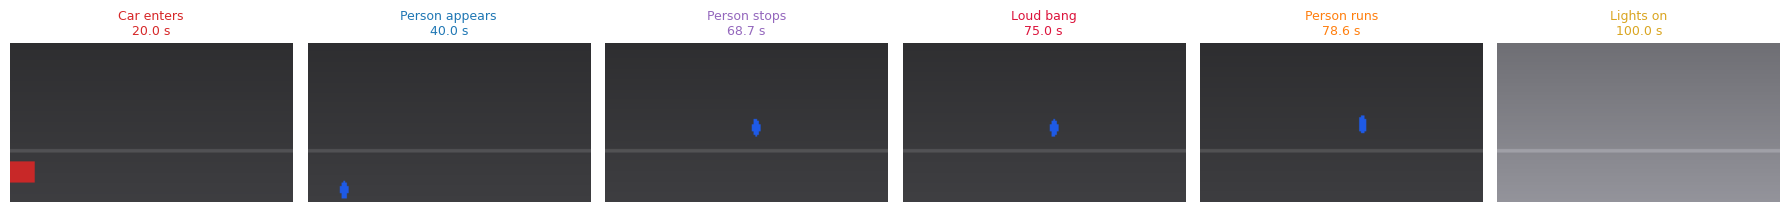

In [4]:
# TODO 1: person speed (px/s)
# Displacement over a 1-second window (FPS frames) = px per second; NaN where the person is not in view
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))

# TODO 2: standing / running time ranges (print the first and last time of each)
standing = speed < 3
running = speed > 25
t = cctv.time_s
print(f"Standing: {t[standing].min():.1f} s -> {t[standing].max():.1f} s")
print(f"Running : {t[running].min():.1f} s -> {t[running].max():.1f} s")

# TODO 3: event frame indices
audio_event_idx = int(np.argmax(cctv.audio_level_db.values > -20))      # first frame above -20 dB
lighting_event_idx = int(np.flatnonzero(cctv.mean_brightness.diff().abs().values > 40)[0])
print(f"Audio event   : frame {audio_event_idx} (t = {t[audio_event_idx]:.2f} s)")
print(f"Lighting event: frame {lighting_event_idx} (t = {t[lighting_event_idx]:.2f} s)")

# Other events used for the timeline: first appearance of the car and of the person
car_idx = int(cctv.car_x.first_valid_index())
person_idx = int(cctv.person_x.first_valid_index())
stand_idx = int(np.flatnonzero(standing.values)[0])
run_idx = int(np.flatnonzero(running.values)[0])
events = [
    (car_idx, "Car enters", "tab:red"),
    (person_idx, "Person appears", "tab:blue"),
    (stand_idx, "Person stops", "tab:purple"),
    (audio_event_idx, "Loud bang", "crimson"),
    (run_idx, "Person runs", "tab:orange"),
    (lighting_event_idx, "Lights on", "goldenrod"),
]

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t, cctv.motion_energy, lw=1, color="0.3")
for k, (i, lab, c) in enumerate(events):
    ax.axvline(t[i], color=c, ls="--", lw=1.2)
    ax.text(t[i], ax.get_ylim()[1] * (0.97 - 0.12 * (k % 3)), " " + lab + f" ({t[i]:.0f}s)", color=c, fontsize=8, va="top")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy")
ax.set_title("Motion energy over 120 s with detected events")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(3 * len(events), 2.4))
for ax, (i, lab, c) in zip(axes, events):
    ax.imshow(render_frame(cctv.iloc[i])); ax.axis("off")
    ax.set_title(f"{lab}\n{t[i]:.1f} s", fontsize=9, color=c)
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_ Uniform sampling at 0, 20, 40, 60, 80, 100 s would most likely miss the **loud bang at 75 s**, the **moment the person stops**, and the **start of the run at about 78.6 s**, because these are short events that fall between sample points. The 100 s lighting jump happens to land on a sample, but only by luck. Uniform sampling is blind to the content, so most of its frames show nothing of interest while the key moments go unrepresented. The approach I used is **content-based keyframe extraction**: pick frames where motion, audio or brightness changes, so the keyframes cluster where something happens.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.99, 'MYSTERY (74.5-76.5 s)': 0.879}
Verdict: GLASS BREAKING - 88% of post-impact energy is above 3 kHz (glass ref 99%, gunshot ref 0%); the mystery clip has a lingering high-frequency tinkle, not a clean crack-and-silence.


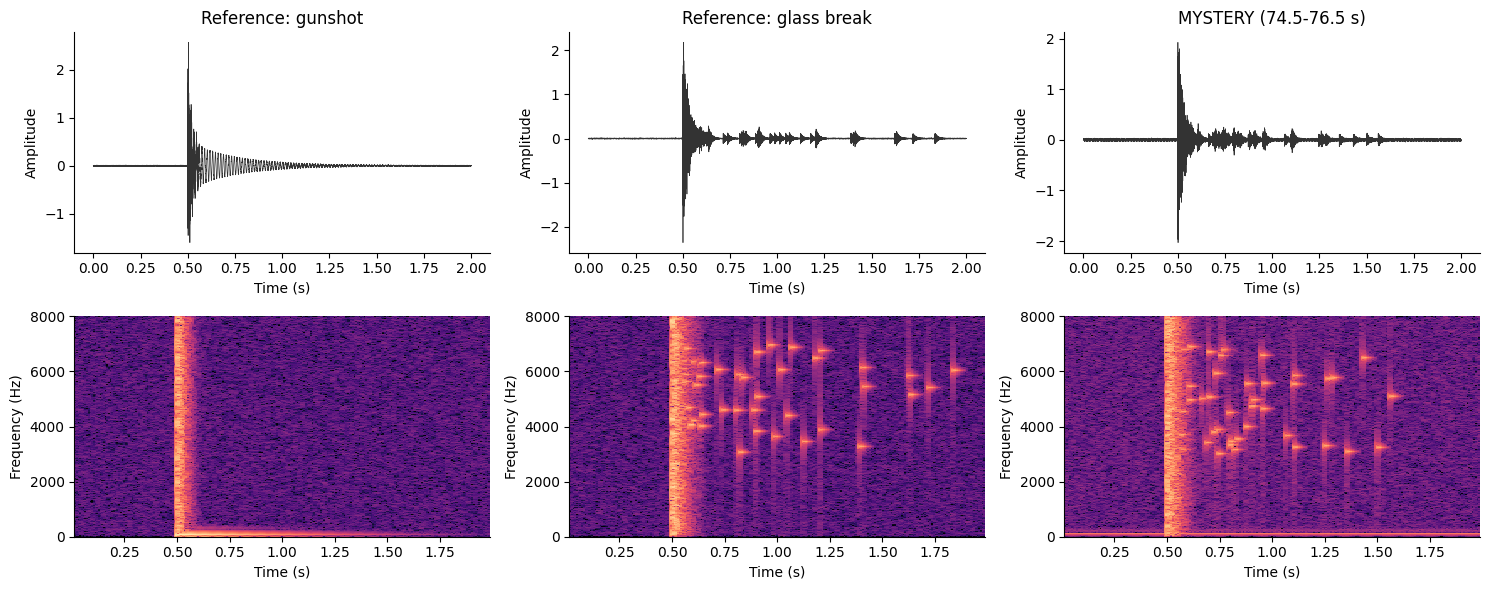

In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for col, (name, x) in enumerate(clips.items()):
    tt = np.arange(x.size) / FS
    axes[0, col].plot(tt, x, lw=0.5, color="0.2")
    axes[0, col].set_title(name); axes[0, col].set_xlabel("Time (s)"); axes[0, col].set_ylabel("Amplitude")
    f, ts, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    axes[1, col].pcolormesh(ts, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-30)
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].set_xlabel("Time (s)"); axes[1, col].set_ylabel("Frequency (Hz)")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    seg = x[int((0.5 + 0.2) * FS): int((0.5 + 1.2) * FS)]
    P = np.abs(np.fft.rfft(seg)) ** 2
    fr = np.fft.rfftfreq(seg.size, 1 / FS)
    hf_fraction[name] = float(P[fr > 3000].sum() / P.sum())

print({k: round(v, 3) for k, v in hf_fraction.items()})
# TODO 4: verdict
m = hf_fraction["MYSTERY (74.5-76.5 s)"]
g = hf_fraction["Reference: gunshot"]; b = hf_fraction["Reference: glass break"]
verdict = "GLASS BREAKING" if abs(m - b) < abs(m - g) else "GUNSHOT"
print(f"Verdict: {verdict} - {m:.0%} of post-impact energy is above 3 kHz "
      f"(glass ref {b:.0%}, gunshot ref {g:.0%}); the mystery clip has a lingering high-frequency tinkle, not a clean crack-and-silence.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_ No. All three waveforms show the same thing: a quiet background, a sudden loud burst at about 0.5 s, and a decay. The waveform shows *when* and *how loud* but not *what kind* of sound. The spectrogram adds **time (x), frequency (y) and magnitude (colour intensity)**. The pattern that decided the verdict was the **scattered high-frequency specks** lingering after the impact, in the mystery clip and in the glass reference, which is the tinkle of falling shards. The gunshot reference instead shows a vertical stripe (a broadband crack) plus a low-frequency boom and then silence. The 3 kHz energy fractions agree: the mystery clip is close to the glass value and far from the gunshot value.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

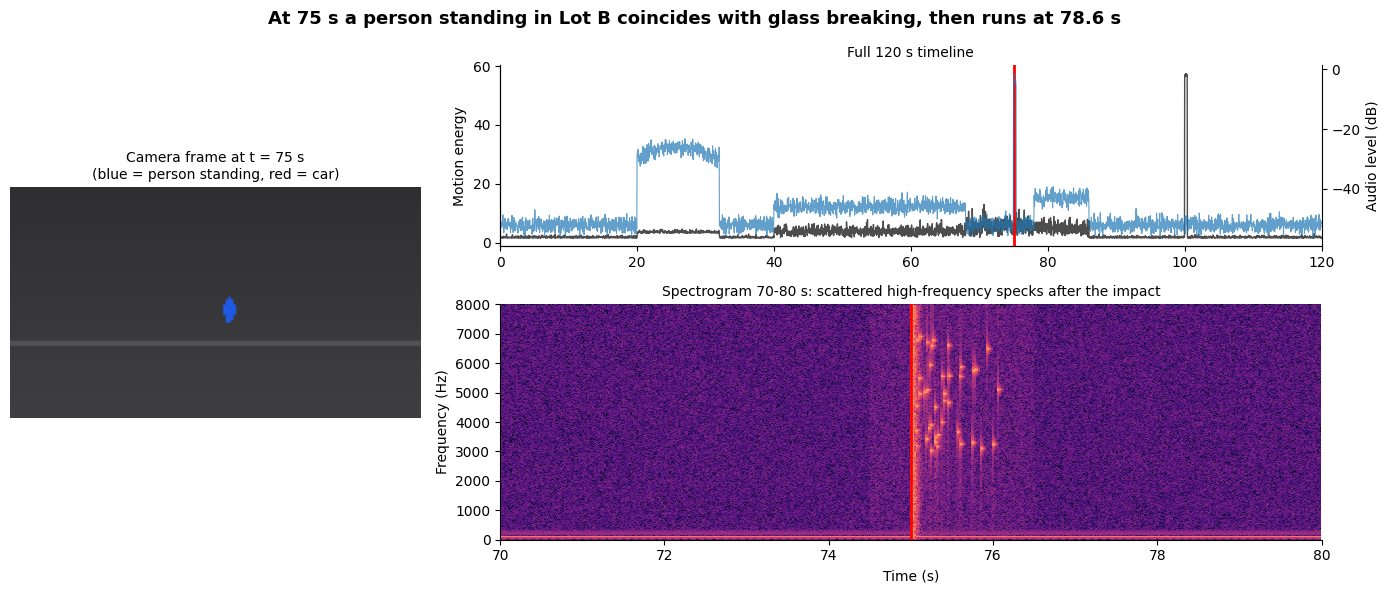

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
# 1) video frame at t = 75 s (left)
ax_v = fig.add_subplot(gs[:, 0])
ax_v.imshow(render_frame(cctv.iloc[int(round(t_sel * FPS))])); ax_v.axis("off")
ax_v.set_title(f"Camera frame at t = {t_sel:.0f} s\n(blue = person standing, red = car)", fontsize=10)

# 2) motion + audio timeline, red marker at 75 s (top right)
ax_t = fig.add_subplot(gs[0, 1])
ax_t.plot(cctv.time_s, cctv.motion_energy, color="0.3", lw=1, label="Motion energy")
ax_t.set_ylabel("Motion energy"); ax_t.set_xlim(0, 120)
ax_a = ax_t.twinx(); ax_a.spines["right"].set_visible(True)
ax_a.plot(cctv.time_s, cctv.audio_level_db, color="tab:blue", lw=0.8, alpha=0.7, label="Audio level (dB)")
ax_a.set_ylabel("Audio level (dB)")
ax_t.axvline(t_sel, color="red", lw=2)
ax_t.set_title("Full 120 s timeline", fontsize=10)

# 3) spectrogram 70-80 s with the same marker (bottom right)
ax_s = fig.add_subplot(gs[1, 1])
seg = (t_audio >= 70) & (t_audio < 80)
f, ts, Sxx = signal.spectrogram(x_audio[seg], fs=FS, nperseg=512, noverlap=384)
ax_s.pcolormesh(70 + ts, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-30)
ax_s.set_ylim(0, 8000); ax_s.set_xlim(70, 80)
ax_s.axvline(t_sel, color="red", lw=2)
ax_s.set_xlabel("Time (s)"); ax_s.set_ylabel("Frequency (Hz)")
ax_s.set_title("Spectrogram 70-80 s: scattered high-frequency specks after the impact", fontsize=10)

# 4) conclusion-style title
fig.suptitle("At 75 s a person standing in Lot B coincides with glass breaking, then runs at 78.6 s", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_ The bang would appear at about 77 s in the audio instead of 75 s, so it would line up with the person standing at the end of the standing period, or with the run starting at 78.6 s, instead of with them standing still. The briefing would then suggest the person fled right after the sound, or that the sound was a reaction to something, which could wrongly implicate or exonerate them. The **top-right timeline** would show it most clearly: the audio spike and the red 75 s marker would not coincide, and the spike would not line up with the motion-energy change. The spectrogram marker would also sit away from the burst of specks.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_ A car entered Lot B at about 20 s, a person appeared at 40 s and stopped near the scene at about 68.7 s, a loud bang at 75.0 s was **glass breaking and not a gunshot**, the person ran from 78.6 s to 86.0 s, and the lights came on at 100 s. I would put the **synchronized view first**, because it follows the structure → pattern → change → event → meaning chain: the timeline gives the overview and the video frame and spectrogram give the detail at the same timestamp, so each claim has two modalities behind it. The spectrogram is what separates glass from a gunshot, since it shows time × frequency × magnitude, and the waveform could not. Storing all 400 cameras at 1080p/30 fps uncompressed would take about 5,866 TB per day, against about 217 TB at 360p/10 fps, so I recommend a tiered policy: low-resolution, low-frame-rate continuous recording, with full-quality clips kept around events detected by motion or audio. That policy must not sacrifice the **temporal and spatial detail around events**, meaning full frame rate and resolution plus synchronized audio for the seconds around a trigger, because a person's actions, identifying detail and the sound timing cannot be recovered from the downsampled footage.